#### In this notebook i will use the lsm.py to see what happens to a gaussian input and the symbol that is recovvered

In [42]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

# print(sys.executable)

In [43]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 

from nonlinear.lsm import LSM
from nonlinear.solvers import KdV, Whitham
from linear.help import *


In [44]:
N = 2**9
P = 20
x = np.linspace(-P/2, P/2, N, endpoint=False)
# x = np.linspace(-3*P/4, P/4, N, endpoint=False)

g = 0.1*np.exp(-x**2)
h = np.cos(2*np.pi * x / P)



In [45]:
kdv1 = KdV(P = P, dt = 1e-3, T = 2, u0 = g, save_every=1)
# kdv1 = Whitham(P = P, dt = 1e-3, T = 5, u0 = g, save_every=1)
t,u = kdv1.splitStep()

kdv2 = KdV(P = P, dt = 1e-3, T = 2, u0 = h, save_every=1)
# kdv2 = Whitham(P = P, dt = 1e-3, T = 5, u0 = h, save_every=1)
t,u2 = kdv2.splitStep()

In [46]:
# animate_solution_nb(x, u2)

In [47]:
lsm = LSM([u], kdv1.dt)
lsm_X = lsm.lsm()



512 512


In [56]:
half = N//2
idx = int(13*np.pi) #(N//2)-1 

idx_p = N//2 + idx
idx_n = N//2 - idx + 1

ell , n = lsm.fit_symbol(k = kdv1.k, idx_range = (idx_n, idx_p), deg = 5)

In [57]:
fit_table(ell, n, part="imag")

,ξ^5,ξ^4,ξ^3,ξ^2,ξ^1,ξ^0
ell,-1.375317e-05,4.155535e-10,0.167353,-4.376573e-08,-1.009308,4.866313e-07
n,-5.248173e-07,-1.371084e-11,0.000137,1.519732e-09,-0.505285,-1.755262e-08


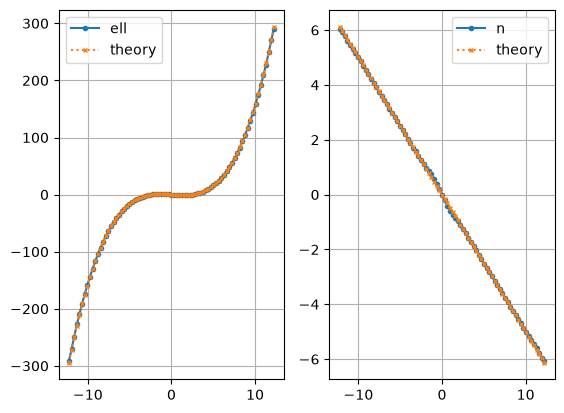

In [58]:
lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)
# lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: -np.sign(k)*np.sqrt(k*np.tanh(k)), n_t = lambda k: -0.5*k)


512 512


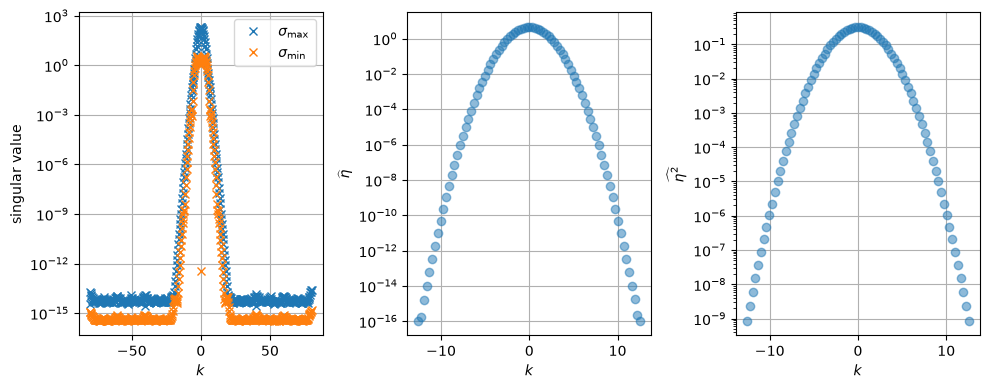

In [59]:
X = lsm.lsm()


order = np.argsort(kdv1.k)
half = kdv1.N//2
k_o = kdv1.k[order]
X_0 = X[order,0]
X_1 = X[order,1]


idx_pos = half + idx +1
idx_neg = half - idx

# print(k_o[idx_pos])

# lsm.plot_symbol_fit(k, idx_range = (idx_neg, idx), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)
# plt.semilogy(k, lsm.cond, 'x', color = 'r')
# plt.axvline(10, linestyle = '--')
# plt.axvline(-10, linestyle = '--')
# plt.grid(True)
# plt.xlabel("k")
# plt.ylabel(r"$\kappa(A_k)$")
# plt.show()

fig, ax = plt.subplots(1,3,figsize = (10,4))

ax[0].semilogy(kdv1.k, lsm.sigma_max, 'x', label=r'$\sigma_{\max}$')
ax[0].semilogy(kdv1.k, lsm.sigma_min, 'x', label=r'$\sigma_{\min}$')

ax[0].set_xlabel(r'$k$')
ax[0].set_ylabel('singular value')
ax[0].legend()
ax[0].grid(True)

for eta in lsm.eta_hat:
    ax[1].semilogy(k_o[idx_neg: idx_pos],np.abs(eta[0,order][idx_neg: idx_pos]), 'o', alpha = 0.5)
    ax[1].set_xlabel(r'$k$')
    ax[1].set_ylabel(r'$\widehat{\eta}$')
    # ax[1].legend()
    ax[1].grid(True)

for eta in lsm.nl_hat:
    ax[2].semilogy(k_o[idx_neg: idx_pos],np.abs(eta[0,order][idx_neg: idx_pos]), 'o', alpha = 0.5)
    ax[2].set_xlabel(r'$k$')
    ax[2].set_ylabel(r'$\widehat{\eta^2}$')
    # ax[2].legend()
    ax[2].grid(True)

plt.tight_layout()
plt.show()

In [60]:
eta = lsm.eta_hat
# animate_solution_nb(k_o[half:int(half+2*np.pi*10)],eta[-1][:,order][:,half:int(half+2*np.pi*10)].real)


In [61]:
# animate_solution_nb(k_o[half:int(half+2*np.pi*10)],eta[0][:,order][:,half:int(half+2*np.pi*10)].real)


[]

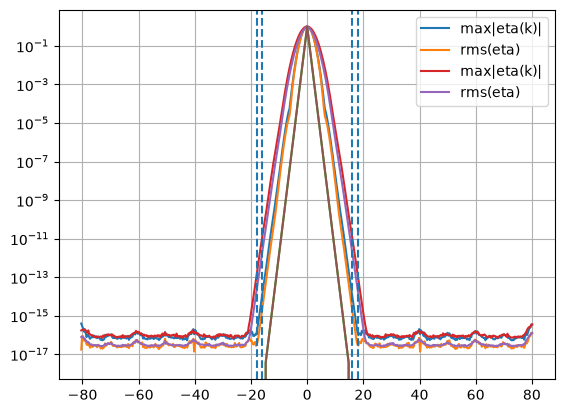

In [62]:
eta_strength = np.max(np.abs(eta[0]), axis = 0)/np.max(np.abs(eta[0]), axis = (0,1))
eta_rms      = np.sqrt(np.mean(np.abs(eta[0])**2, axis=0))/np.max(np.abs(eta[0]), axis = (0,1))

nl = lsm.nl_hat[0]

nl_strength = np.max(np.abs(nl), axis = 0)/np.max(np.abs(nl), axis = (0,1))
nl_rms      = np.sqrt(np.mean(np.abs(nl)**2, axis=0))/np.max(np.abs(nl), axis = (0,1))
# print(eta.shape)

plt.semilogy(kdv1.k[order],eta_strength[order], label = r"max|eta(k)|")
plt.semilogy(kdv1.k[order],eta_rms[order], label = r'rms(eta)')
plt.semilogy(kdv1.k[order] , np.exp(-np.e*(np.abs(kdv1.k[order])))*(np.abs(kdv1.k[order]) < 15)) # The modes are decaying like exp(-a|k|)
plt.semilogy(kdv1.k[order],nl_strength[order], label = r"max|eta(k)|")
plt.semilogy(kdv1.k[order],nl_rms[order], label = r'rms(eta)')
plt.semilogy(kdv1.k[order] , np.exp(-np.e*(np.abs(kdv1.k[order])))*(np.abs(kdv1.k[order]) < 15)) # The modes are decaying like exp(-a|k|)
plt.axvline(-16, linestyle = '--')
plt.axvline(16,linestyle = '--')
plt.axvline(-18, linestyle = '--')
plt.axvline(18,linestyle = '--')
plt.grid()
plt.legend()
plt.plot()


In [63]:
N = len(eta_strength)
i = 13*4-1
print(10*'-')
print(eta_strength[order][N//2+i:N//2+i+8])
print(10*'-')

print(kdv1.k[order][N//2+i])

j = 15*4
print(10*'-')
print(nl_strength[order][N//2+j:N//2+j + 8])
print(10*'-')

print(kdv1.k[order][N//2+j])

----------
[1.15805948e-14 5.55853972e-15 2.62062067e-15 1.24167769e-15
 5.73892039e-16 2.83850692e-16 1.38650180e-16 9.66155015e-17]
----------
16.022122533307947
----------
[1.65630714e-14 8.30402198e-15 4.15945132e-15 2.07636777e-15
 1.07600991e-15 6.00753457e-16 3.00237549e-16 1.83788849e-16]
----------
18.84955592153876
